In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
FIG_DIR = Path("../screenshots/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/processed/heart_disease_clean.csv")
df.shape, df.head()

Matplotlib is building the font cache; this may take a moment.


((303, 14),
     age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
 0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
 1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
 2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
 3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
 4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
 
    slope   ca  thal  target  
 0    3.0  0.0   6.0       0  
 1    2.0  3.0   3.0       1  
 2    2.0  2.0   7.0       1  
 3    3.0  0.0   3.0       0  
 4    1.0  0.0   3.0       0  )

# Heart Disease UCI: Exploratory Data Analysis
This notebook explores the cleaned Cleveland heart disease dataset (303 patients, 13 features plus a binary target). It covers data overview, class balance, numeric distributions, correlations, and disease rates by category. Findings here guide the feature engineering and model choices in the next step.

In [2]:
display(df.describe().T)
display(df.isna().sum())
df.dtypes

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

### Data overview
The cleaned dataset has 303 patients and 14 columns. Only `ca` (4 values) and `thal` (2 values) have missing entries, which is under 2% of rows. I am leaving them unfilled for now and will impute inside the modelling pipeline, so the fill values are learned from training data only and nothing leaks from the test folds.

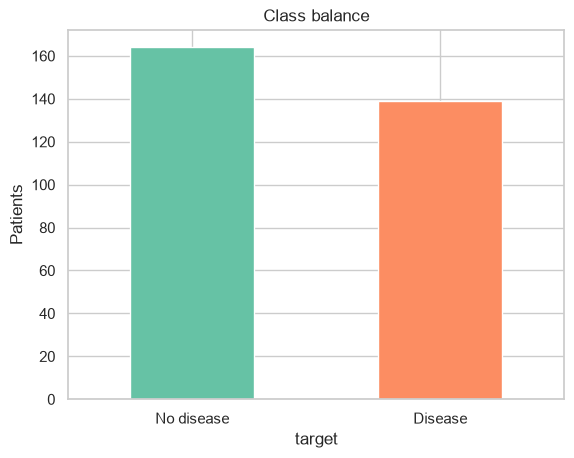

In [3]:
ax = df["target"].value_counts().sort_index().plot(
    kind="bar", color=["#66c2a5", "#fc8d62"], rot=0)
ax.set_xticklabels(["No disease", "Disease"])
ax.set_ylabel("Patients")
ax.set_title("Class balance")
plt.savefig(FIG_DIR / "class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

### Class balance
The target is close to balanced, with 164 patients without heart disease and 139 with it (about 54% vs 46%). Because neither class dominates, plain accuracy is a reasonable metric here, but I will still report precision, recall and ROC-AUC, since missing a true disease case is costlier than a false alarm.

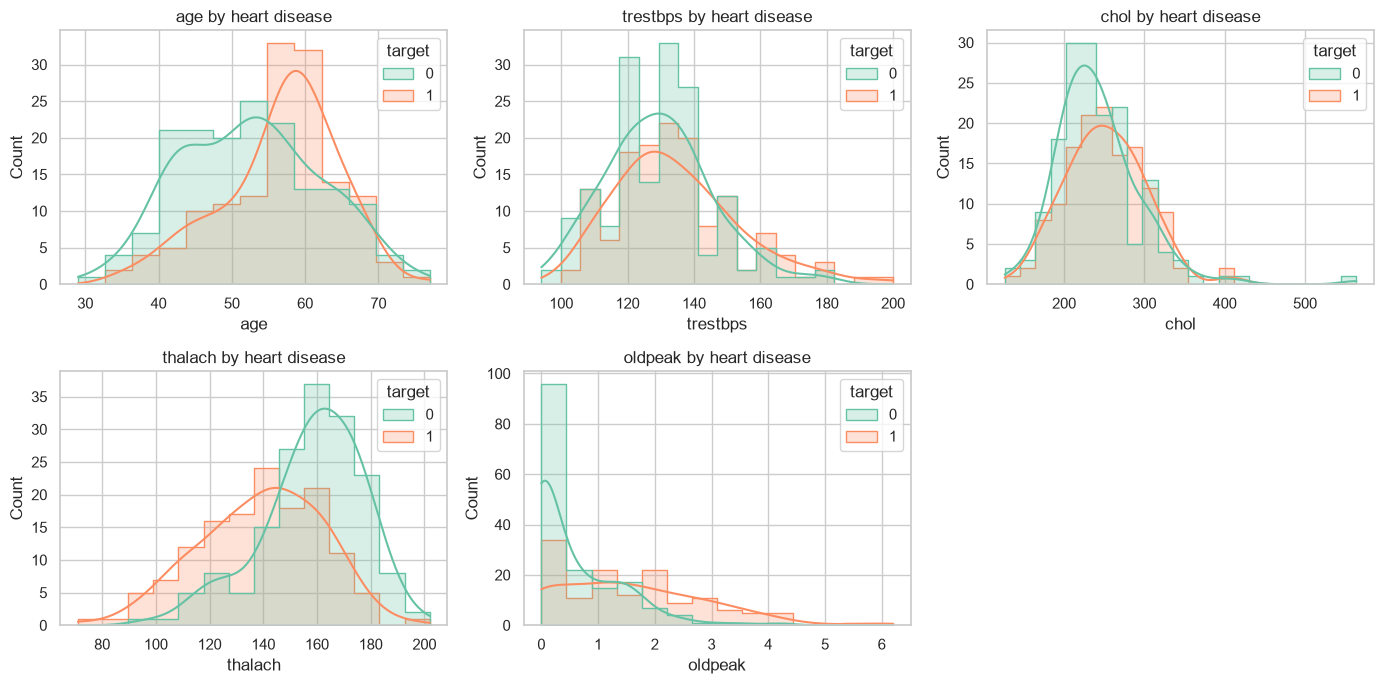

In [4]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax, element="step")
    ax.set_title(f"{col} by heart disease")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "histograms.png", dpi=150, bbox_inches="tight")
plt.show()

### Numeric feature distributions
Maximum heart rate (`thalach`) tends to be lower in patients with disease, and ST depression (`oldpeak`) tends to be higher. Both distributions show clear separation between the two classes. Age shifts slightly older for the disease group. Resting blood pressure (`trestbps`) and cholesterol (`chol`) overlap heavily between classes, so they are weaker predictors on their own. `chol` and `oldpeak` are right-skewed with a few high outliers, which supports scaling the numeric features before fitting Logistic Regression.

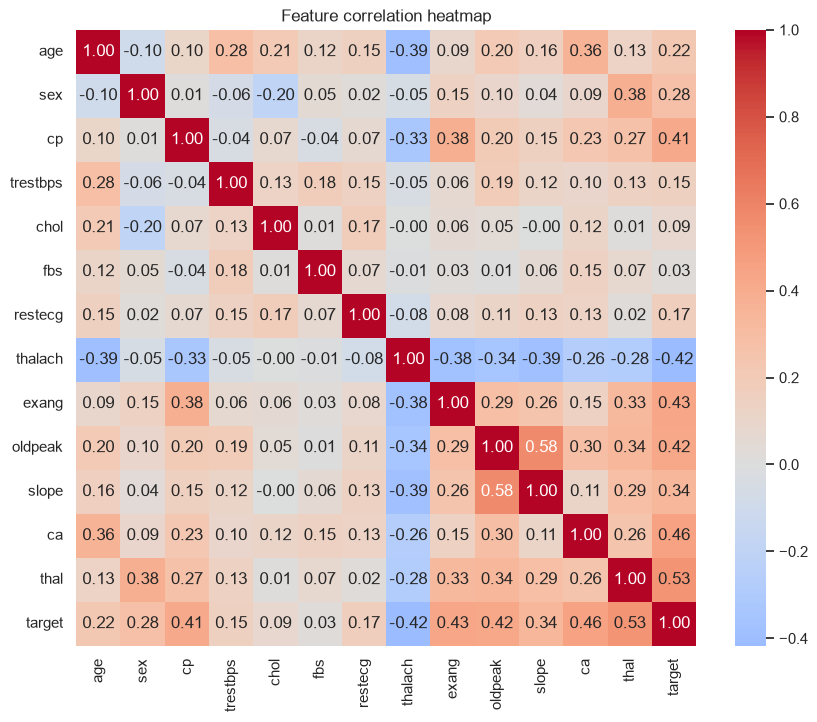

In [5]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation heatmap")
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Correlation heatmap
The features most positively correlated with `target` are `ca`, `thal`, `oldpeak`, `cp` and `exang`, while `thalach` is negatively correlated (lower max heart rate goes with disease). Correlations between the predictors themselves are mostly moderate, so multicollinearity does not look severe. Notably, `slope` and `oldpeak` are related to each other, which I will keep in mind when interpreting Logistic Regression coefficients.

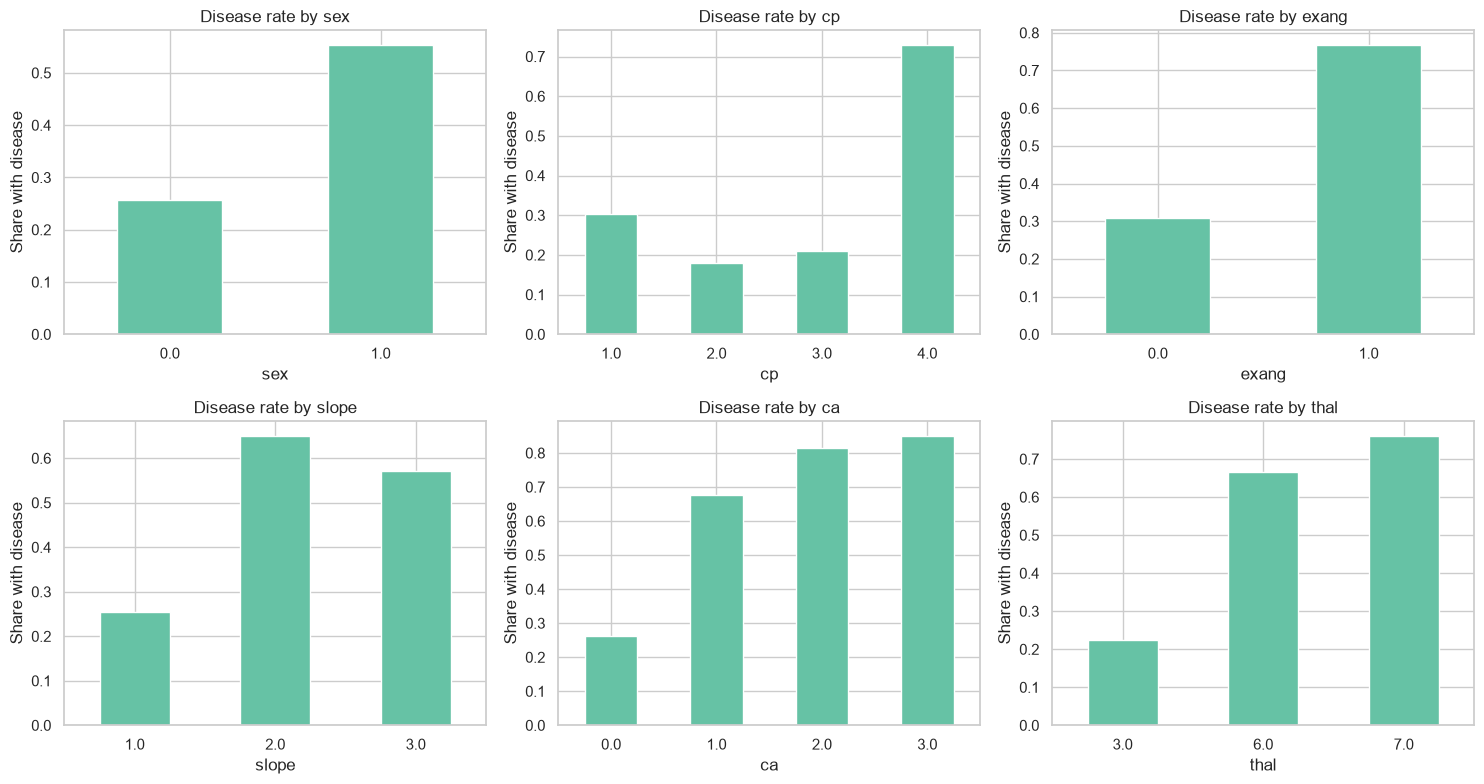

In [6]:
cat_cols = ["sex", "cp", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["target"].mean()
    rate.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"Disease rate by {col}")
    ax.set_ylabel("Share with disease")
plt.tight_layout()
plt.savefig(FIG_DIR / "disease_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

### Disease rate by category
Disease prevalence differs sharply across categorical features. The number of coloured vessels (`ca`) shows a steady dose-response pattern, rising from about a quarter of patients at 0 vessels to over 80% at 3. Exercise-induced angina, thalassemia defects (`thal` = 6 or 7) and asymptomatic chest pain (`cp` = 4) are all strongly associated with disease, and males show roughly double the rate of females. Some categories, such as `ca` = 3, contain few patients, so those bars are noisier than they look. These features will likely carry much of the model's predictive signal.